# MATH 60231 – Homework #2
**Group:** Mathis Huot, Nathan Madore, Isabelle Tanara

Due: Friday, November 13, 2026 (11:59pm Montréal time)

# Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.ar_model import AutoReg, ar_select_order
from statsmodels.tsa.api import VAR
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, LeaveOneOut, cross_val_score
from scipy import stats

## Table formatting function 

Source used for Table Formatting: [MatPlotLib - Table Demo](https://matplotlib.org/stable/gallery/misc/table_demo.html)

In [2]:
# Table formatting template (Sourced from MatPlotLib, linked above)
import os, re
os.makedirs("Output", exist_ok=True)                       # every table and figure is also saved as a PNG in Output/

def save_output(fig, label):
    """Save a matplotlib figure as a PNG in the Output/ folder.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Figure to save.
    label : str
        Table/figure title; turned into a safe file name
        (e.g. "Table 2.4 - AR models" -> "Output/Table_2.4_AR_models.png").
    """
    # File name built from the label: "Table 2.4 – AR models ..." -> Output/Table_2.4_AR_models_....png
    name = re.sub(r"[^A-Za-z0-9.]+", "_", label).strip("_.")[:90]
    
    fig.savefig(f"Output/{name}.png", dpi=200, bbox_inches="tight")


def table_figure(df, title, row_labels=None, decimals=6, col_colors=None, figsize=(12, 2.2)):
    """Render a DataFrame as a table image, save it to Output/ and display it.

    Parameters
    ----------
    df : pd.DataFrame
        Numbers to show (NaN cells are printed as "-").
    title : str
        Title above the table; also used as the file name.
    row_labels : list, optional
        Row labels to use instead of df.index.
    decimals : int
        Number of decimals shown in each cell.
    col_colors : list, optional
        Background colour of each column header.
    figsize : tuple
        Figure size in inches.
    """
    cell_text = []
    
    for row in df.values:
        row_text = []
        
        for x in row:
            if pd.notna(x):
                row_text.append(f"{x:,.{decimals}f}")      # number with thousands separator
            else:
                row_text.append("-")                       # "-" for empty cells
        
        cell_text.append(row_text)
    
    if row_labels is None:
        row_labels = list(df.index.astype(str))
    else:
        row_labels = list(row_labels)

    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off")
    table = ax.table(cellText=cell_text,
                     rowLabels=row_labels,
                     colLabels=list(df.columns),
                     colColours=col_colors,
                     loc="center",
                     cellLoc="center",
                     rowLoc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.4)
    ax.set_title(title, pad=20)
    plt.tight_layout()
    save_output(fig, title)                                 # save to Output/ before displaying
    plt.show()

## Data loading

In [3]:
stock_data = pd.read_csv('Data/individual_stocks_data.csv').rename(columns={
    "DlyCalDt": "Date",
    "DlyRet": "Stock Total Return",
})

NFLX_data = stock_data[["Date", "Stock Total Return"]][stock_data['Ticker'] == 'NFLX'].copy()

# Validation of the data extracted
print(NFLX_data.head())

            Date  Stock Total Return
4536  2013-12-02           -0.005139
4537  2013-12-03           -0.002693
4538  2013-12-04           -0.018378
4539  2013-12-05            0.005024
4540  2013-12-06           -0.010110


In [4]:
PJM_data = pd.read_csv('Data/PJM.csv',
                       skipinitialspace=True, 
                       parse_dates=['Date'], 
                       index_col='Date')
PJM_data.columns = ["price", "S_load", "Z_load"]                # Columns in the order they appear in the file
daily_PJM_data = PJM_data.resample('D').mean()                  # From hourly to daily average
df_pjm = daily_PJM_data[['price', 'Z_load', 'S_load']].dropna() # Problem 3 variables, in the VAR ordering [price, Z_load, S_load]

# Validation of the data extracted
print(daily_PJM_data.head())

                price         S_load        Z_load
Date                                              
2013-01-01  27.175540   92435.625000  11795.291667
2013-01-02  33.734351  103247.625000  12565.541667
2013-01-03  29.849249  103640.708333  12502.583333
2013-01-04  28.198551  102280.958333  12286.833333
2013-01-05  26.124395   93045.041667  11032.708333


# Problem 1 – Machine Learning [30 pts]
Same stock as HWK1 (Problems 2c–2f) throughout. Remind the reader which stock and why.

## 1a. `Q1_Factors()` [5 pts]
Function taking a Series `ser` and integer `n`; returns a DataFrame with 1+2n columns: `ser`, its lags 1..n, and its squared lags 1..n.

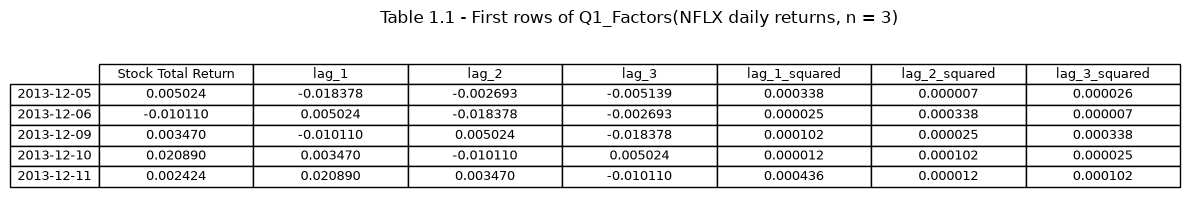

In [5]:
def Q1_Factors(ser, n):
    """Build the regressor DataFrame for Problem 1: the series, its lags and squared lags.

    Parameters
    ----------
    ser : pd.Series
        Daily returns.
    n : int
        Number of lags.

    Returns
    -------
    pd.DataFrame
        1 + 2n columns: ser, lag_1..lag_n, lag_1_squared..lag_n_squared.
        The first n rows (incomplete lags) are dropped.
    """
    df = pd.DataFrame(ser)
    
    for i in range(1, n + 1):   # columns 2 to n lagged values of ser
        df[f'lag_{i}'] = ser.shift(i)
    
    for i in range(1, n + 1):   # columns n+1 to 2n squared lagged values of ser
        df[f'lag_{i}_squared'] = ser.shift(i) ** 2
    
    df = df.dropna()
    
    return df


# Calling the table formatting function above
# "Report the first few rows of the resulting DataFrame for n = 3"
n = 3
head_1a = Q1_Factors(NFLX_data['Stock Total Return'], n).head()
dates_1a = NFLX_data.loc[head_1a.index, 'Date']             # dates instead of row numbers

table_figure(head_1a,
    "Table 1.1 - First rows of Q1_Factors(NFLX daily returns, n = 3)",
    row_labels=dates_1a)


## 1b. `Q1_OLS()` [5 pts]
Function taking a one-column DataFrame `df` and integer `n`; returns the OLS `RegressionResults` of `df` on a constant + the 2n regressors from `Q1_Factors()`. Apply with n = 3.

Source used: [GeeksforGeeks: OLS](https://www.geeksforgeeks.org/data-science/ordinary-least-squares-ols-using-statsmodels/)

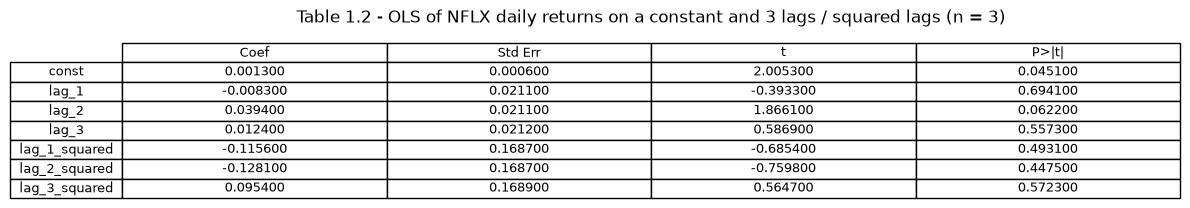

                            OLS Regression Results                            
Dep. Variable:     Stock Total Return   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.9141
Date:                Fri, 13 Nov 2026   Prob (F-statistic):              0.484
Time:                        17:37:23   Log-Likelihood:                 4849.9
No. Observations:                2265   AIC:                            -9686.
Df Residuals:                    2258   BIC:                            -9646.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.0013      0.001      2.005

<Figure size 800x700 with 0 Axes>

In [6]:
def Q1_OLS(df, n):
    """Regress a series on a constant, its n lags and its n squared lags by OLS.

    Parameters
    ----------
    df : pd.DataFrame
        One-column DataFrame holding the series.
    n : int
        Number of lags passed to Q1_Factors().

    Returns
    -------
    statsmodels RegressionResults
        Fitted OLS model (coefficients, standard errors, R², ...).
    """
    ser = df.iloc[:, 0]                       # the single column of df, as a Series
    factors = Q1_Factors(ser, n)              # 1+2n columns, NaN rows already dropped
    y = factors.iloc[:, 0]                    # column 1: the values of df
    X = sm.add_constant(factors.iloc[:, 1:])  # constant + 2n lagged and squared-lagged values
    
    return sm.OLS(y, X).fit()                 # RegressionResults object - GeeksforGeeks: OLS


# Calling the regression function above
# "Apply your function using n = 3"
n = 3
res_1b = Q1_OLS(NFLX_data[['Stock Total Return']], n)   # double brackets keep it a one-column DataFrame

coef_1b = pd.DataFrame({
    'Coef':    res_1b.params,
    'Std Err': res_1b.bse,
    't':       res_1b.tvalues,
    'P>|t|':   res_1b.pvalues,
}).round(4)

table_figure(coef_1b,
    "Table 1.2 - OLS of NFLX daily returns on a constant and 3 lags / squared lags (n = 3)")

print(res_1b.summary())

# Saving the full OLS summary as an image in Output/
fig = plt.figure(figsize=(8, 7))
fig.text(0, 1, str(res_1b.summary()), family="monospace",
        fontsize=9, va="top", ha="left")
save_output(fig, "Table 1.2b - Full statsmodels OLS summary (NFLX, n = 3)")
plt.show()

## 1c. `Q1_Ridge()` [10 pts]
Function taking `df`, scalar `s`, integer `n`; plots Ridge coefficient paths over n values of λ in [0, s]. Apply to the part (a) DataFrame with n = 200 and s large enough for full shrinkage.

Source used: [ScikitLearn - Plot Ridge Coefficients](https://scikit-learn.org/stable/auto_examples/linear_model/plot_ridge_path.html)

Source used: [DataCamp - Linspace Function](https://www.datacamp.com/tutorial/how-to-use-the-numpy-linspace-function?utm_cid=23487274749&utm_aid=192541861336&utm_campaign=230119_1-ps-dscia~dsa-tofu~python_2-b2c_3-nam_4-prc_5-na_6-na_7-le_8-pdsh-go_9-nb-e_10-na_11-na&utm_loc=1002599-&utm_mtd=-c&utm_kw=&utm_source=google&utm_medium=paid_search&utm_content=ps-dscia~nam-en~dsa~tofu~tutorial~python&gad_source=1&gad_campaignid=23487274749&gbraid=0AAAAADQ9WsE9WiZ97oRYtAHCRqqX8mU7F&gclid=Cj0KCQiAwdDXBhDuARIsAFdLukk5uwT-3hWztMh_VrmpDAQjXKkIuNT2a79Rm-FM5db5aNQQs1bJ60MaAikwEALw_wcB)

`Source used: BOOK - An Introduction to Statistical Learning - Ridge Regression (Section 6.2.1 p.248)`

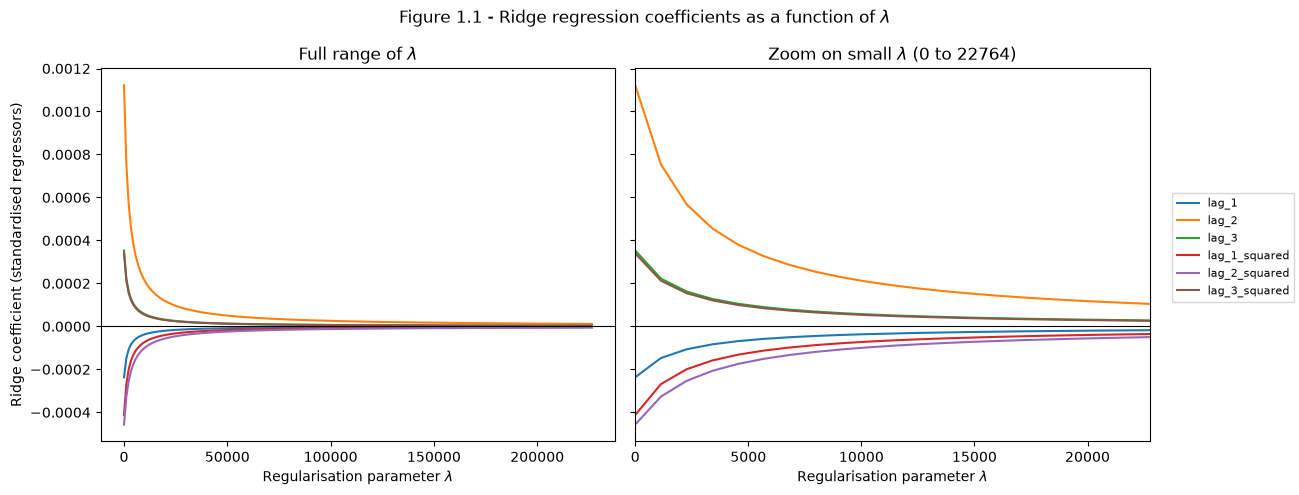

In [7]:
def Q1_Ridge(df, s, n, standardize=True):
    """Compute and plot Ridge coefficient paths over a grid of lambda values.

    Parameters
    ----------
    df : pd.DataFrame
        First column = dependent variable, other columns = regressors.
    s : float
        Largest lambda in the grid (large enough to shrink all coefficients to ~0).
    n : int
        Number of lambda values between 0 and s.
    standardize : bool
        If True, regressors are standardised so the penalty treats them equally.

    Returns
    -------
    pd.DataFrame
        One row per lambda, one column per regressor (Ridge coefficients).
        Also saves and shows Figure 1.1.
    """
    y = df.iloc[:, 0].to_numpy(float)              # Dependent variable: first column
    X = df.iloc[:, 1:].to_numpy(float)             # Independent variables: all other columns
    names = df.columns[1:]

    if standardize:                                # Putting every regressor on the same scale
        X = (X - X.mean(axis=0)) / X.std(axis=0)

    # Centre X and y: the constant is then left unpenalised and drops out of the problem
    Xc, yc = X - X.mean(axis=0), y - y.mean()

    lambdas = np.linspace(0, s, n)
    XtX, Xty = Xc.T @ Xc, Xc.T @ yc
    I = np.eye(Xc.shape[1])
    
    # Closed-form ridge solution for every lambda: (X'X + lambda*I)^(-1) X'y
    rows = []
    for lam in lambdas:
        rows.append(np.linalg.solve(XtX + lam * I, Xty))
    coefs = pd.DataFrame(rows, index=pd.Index(lambdas, name='lambda'), columns=names)

    
    # Plotting the coefficient paths: full range (left) and zoom on the start (right)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    axes[0].plot(coefs.index, coefs.values)
    axes[0].set_title(r'Full range of $\lambda$')

    zoom = lambdas[n // 10]                        # the first 10% of the lambda grid
    axes[1].plot(coefs.index, coefs.values)
    axes[1].set_xlim(0, zoom)
    axes[1].set_title(r'Zoom on small $\lambda$ (0 to %.0f)' % zoom)

    for ax in axes:
        ax.axhline(0, color='black', lw=0.8)
        ax.set_xlabel(r'Regularisation parameter $\lambda$')
    
    axes[0].set_ylabel('Ridge coefficient (standardised regressors)')
    fig.legend(names, loc='center right', fontsize=8)
    fig.suptitle(r'Figure 1.1 - Ridge regression coefficients as a function of $\lambda$')
    plt.tight_layout(rect=[0, 0, 0.9, 1])
    save_output(fig, "Figure 1.1 - Ridge coefficient paths")
    plt.show()
    
    return coefs


# Calling the ridge function above
# "n = 200 and s large enough that all coefficients have visibly shrunk to near zero"
df_1a = Q1_Factors(NFLX_data['Stock Total Return'], 3)     # lagged DataFrame from part (a)
s = 100 * len(df_1a)                                       # see note on s below
coefs_1c = Q1_Ridge(df_1a, s, 200)

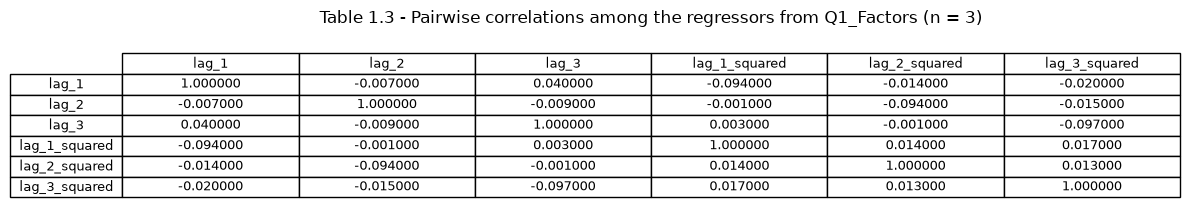

In [8]:
# Pairwise correlation matrix of the n = 3 regressors 
corr_1c = df_1a.iloc[:, 1:].corr()
table_figure(corr_1c.round(3), "Table 1.3 - Pairwise correlations among the regressors from Q1_Factors (n = 3)")

In [9]:
sq = NFLX_data['Stock Total Return'] ** 2
acf_sq = []
for k in (1, 2, 3):
    acf_sq.append(round(sq.autocorr(lag=k), 3))
print("ACF of squared returns, lags 1-3:", acf_sq)

ab = NFLX_data['Stock Total Return'].abs()
acf_abs = []
for k in range(1, 11):
    acf_abs.append(round(ab.autocorr(lag=k), 3))
print("ACF of |returns|, lags 1-10:", acf_abs)

ACF of squared returns, lags 1-3: [np.float64(0.014), np.float64(0.016), np.float64(0.014)]
ACF of |returns|, lags 1-10: [np.float64(0.105), np.float64(0.114), np.float64(0.111), np.float64(0.128), np.float64(0.109), np.float64(0.106), np.float64(0.087), np.float64(0.063), np.float64(0.061), np.float64(0.083)]


## 1d. `Q1_RidgeCV()` [10 pts]
Function taking `df`, `s`, `n`, Boolean `LOOCV`; returns optimal λ* and the Ridge coefficients at λ*. Candidate λ's evenly spaced in [1e-8, s]. LOOCV if True, otherwise 10-fold CV.

Source used: [ScikitLearn - KFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html)

lambda* LOOCV = 11325.00   lambda* 10-fold = 11325.00   (N = 2265)


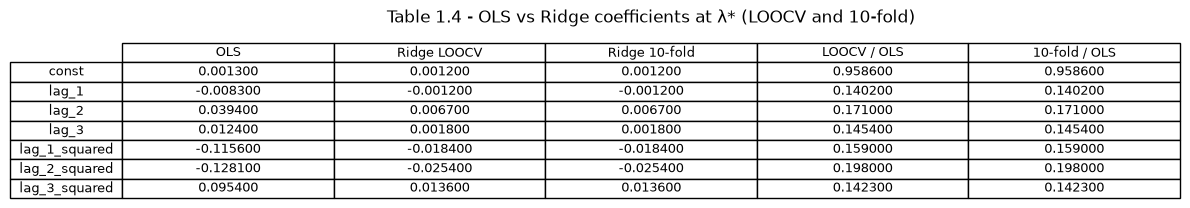

In [10]:
def ridge_beta(X, y, lam):
    """Closed-form Ridge estimate (X'X + lam*P)^(-1) X'y, with the constant left unpenalised.

    Parameters
    ----------
    X : np.ndarray
        Regressor matrix whose first column is the constant (ones).
    y : np.ndarray
        Dependent variable.
    lam : float
        Penalty lambda.

    Returns
    -------
    np.ndarray
        Coefficients [constant, slopes...].
    """
    P = np.eye(X.shape[1])
    P[0, 0] = 0                                        # expected: the constant (column 0) is not penalised
    
    return np.linalg.solve(X.T @ X + lam * P, X.T @ y)


def Q1_RidgeCV(df, s, n, LOOCV):
    """Choose the Ridge penalty lambda by cross-validation and refit at the best lambda.

    Parameters
    ----------
    df : pd.DataFrame
        First column = dependent variable, other columns = regressors.
    s : float
        Largest lambda in the grid.
    n : int
        Number of lambda values between ~0 and s.
    LOOCV : bool
        True -> leave-one-out CV (shortcut formula, no refitting);
        False -> 10-fold CV.

    Returns
    -------
    lam_star : float
        Lambda with the smallest CV mean squared error.
    coefs : pd.Series
        Ridge coefficients at lam_star, converted back to the original
        (unstandardised) units so they are comparable to OLS.
    """
    y = df.iloc[:, 0].to_numpy(float)                  # dependent variable: first column
    X = df.iloc[:, 1:].to_numpy(float)                 # independent variables: the other columns
    mean, std = X.mean(axis=0), X.std(axis=0)
    
    X = (X - mean) / std                               # standardise so all regressors share a scale
    X = np.column_stack([np.ones(len(y)), X])          # add the constant as a column of ones

    lambdas = np.linspace(1e-8, s, n)
    cv_error = []

    for lam in lambdas:
        if LOOCV:
            # leave-one-out without refitting: error_i = residual_i / (1 - h_i)
            P = np.eye(X.shape[1]); P[0, 0] = 0
            A_inv = np.linalg.inv(X.T @ X + lam * P)
            h = np.sum((X @ A_inv) * X, axis=1)        # leverage of each observation
            resid = y - X @ (A_inv @ X.T @ y)
            
            cv_error.append(np.mean((resid / (1 - h)) ** 2))
        
        else:
            # 10-fold CV: fit on 9 folds, test on the 10th
            errors = []
            for train, test in KFold(10, shuffle=True, random_state=0).split(X):
                beta = ridge_beta(X[train], y[train], lam)
                errors.append(np.mean((y[test] - X[test] @ beta) ** 2))
            
            cv_error.append(np.mean(errors))

    lam_star = lambdas[np.argmin(cv_error)]

    # final fit at lambda*, then convert back to the original units (comparable to OLS)
    beta = ridge_beta(X, y, lam_star)
    slopes = beta[1:] / std
    const = beta[0] - np.sum(slopes * mean)
    
    return lam_star, pd.Series([const, *slopes], index=['const', *df.columns[1:]])


# Applying the function to the lagged DataFrame from part (a)
s = 5 * len(df_1a)                                    
lam_loo, beta_loo = Q1_RidgeCV(df_1a, s, 200, True)
lam_kf,  beta_kf  = Q1_RidgeCV(df_1a, s, 200, False)

print(f"lambda* LOOCV = {lam_loo:.2f}   lambda* 10-fold = {lam_kf:.2f}   (N = {len(df_1a)})")
comp = pd.DataFrame({'OLS': res_1b.params, 'Ridge LOOCV': beta_loo, 'Ridge 10-fold': beta_kf})
comp['LOOCV / OLS'] = comp['Ridge LOOCV'] / comp['OLS']      # share of the OLS coefficient kept
comp['10-fold / OLS'] = comp['Ridge 10-fold'] / comp['OLS']

# Calling the table formatting function above
table_figure(comp.round(4), "Table 1.4 - OLS vs Ridge coefficients at λ* (LOOCV and 10-fold)")

# Problem 2 – AR Models [40 pts]
Daily-averaged PJM data; `price` series unless stated otherwise.

## 2a. Descriptive statistics & graphs [5 pts]
Descriptive statistics and labelled time-series plots for `price`, `S_load`, `Z_load`.

In [11]:
#Source used: 
# [Pandas - describe](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)
# [Statsmodels - plot_acf](https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_acf.html)
# [PJM - Analysis of Operational Events and Market Impacts During the January 2014 Cold Weather Events](https://www.pjm.com/-/media/library/reports-notices/weather-related/20140509-analysis-of-operational-events-and-market-impacts-during-the-jan-2014-cold-weather-events.ashx)

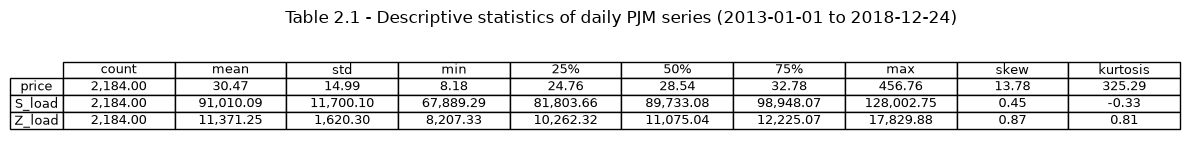

In [12]:
# Define labels (used in the titles of Figures 2.1 and 2.2)
labels = {"price":  "COMED zonal price ($/MWh)",
          "S_load": "PJM system-wide load forecast (MW)",
          "Z_load": "COMED zonal load forecast (MW)"}

# Descriptive stats
statsdata = daily_PJM_data.describe().T
statsdata["skew"] = daily_PJM_data.skew()
statsdata["kurtosis"] = daily_PJM_data.kurt()
# calling the table formatting function above
table_figure(statsdata, "Table 2.1 - Descriptive statistics of daily PJM series (2013-01-01 to 2018-12-24)",
             decimals=2, 
             figsize=(12, 1.6))


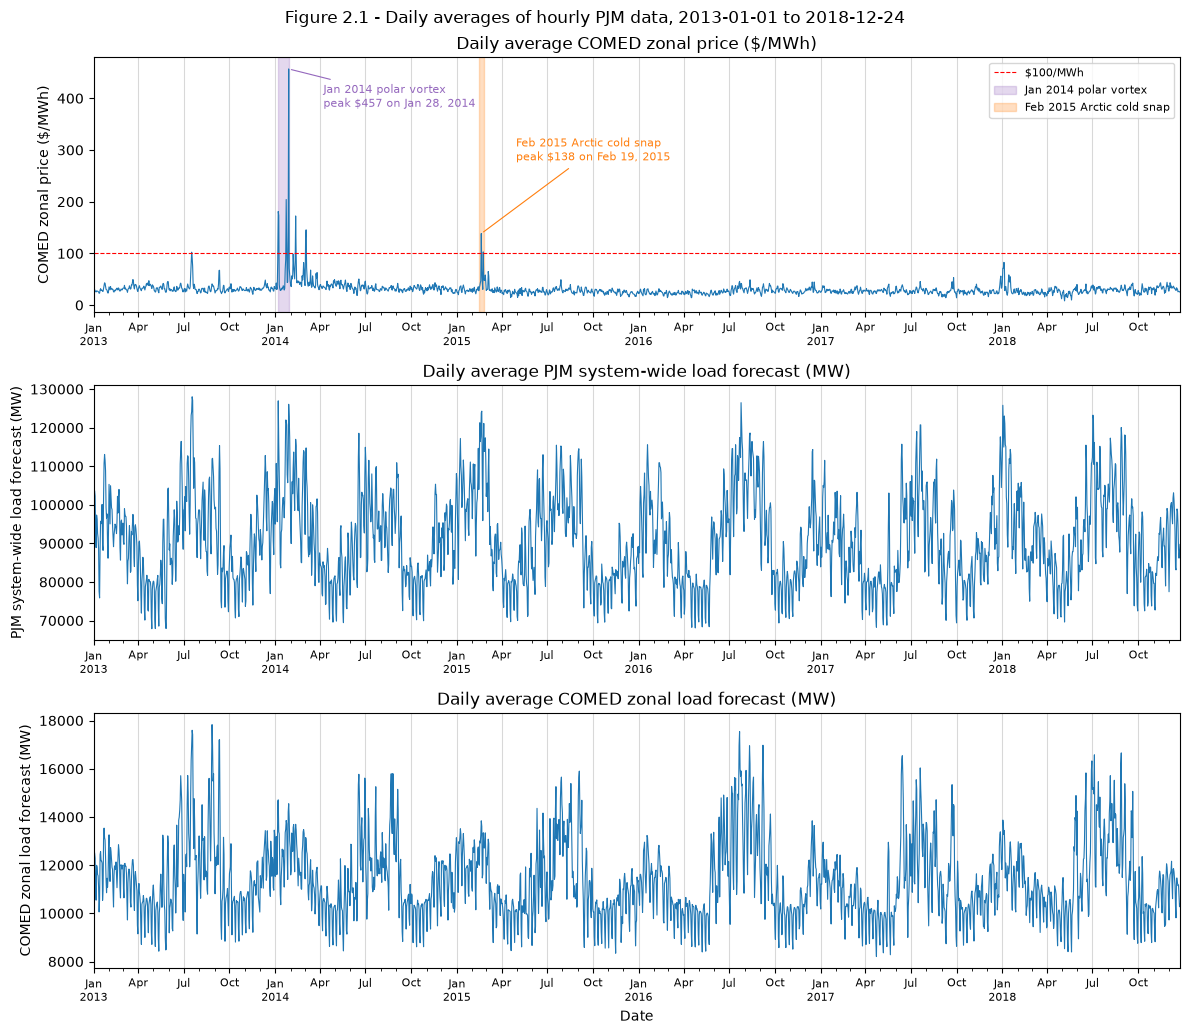

In [13]:
import matplotlib.dates as mdates

# Date labels: month name at each quarter, plus the year under every January ("Jan\n2014")
def quarter_label(x, pos):
    """Tick-label formatter for date axes: month name, plus the year under January.

    Parameters
    ----------
    x : float
        Tick position (matplotlib date number).
    pos : int
        Tick index (required by matplotlib, unused).

    Returns
    -------
    str
        e.g. "Apr" or "Jan\n2015".
    """
    d = mdates.num2date(x)
    if d.month == 1:
        return f"{d:%b}\n{d:%Y}"
    else:
        return f"{d:%b}"


# Extreme cold-weather events behind the price spikes (see Table 2.2 and the PJM report in the sources)
# name: (start, end, colour, label offset in points from the peak)
events = {"Jan 2014 polar vortex":     ("2014-01-06", "2014-01-29", "tab:purple", (25, -10)),   # cold waves: Jan 6-8, 21-24, 27-29
          "Feb 2015 Arctic cold snap": ("2015-02-15", "2015-02-24", "tab:orange", (25, 70))}

# Time series plots
fig, axes = plt.subplots(3, 1, figsize=(12, 10.5), sharex=True)
for ax, col in zip(axes, labels):
    ax.plot(daily_PJM_data.index, daily_PJM_data[col], lw=0.8)
    ax.set_ylabel(labels[col])
    ax.set_title(f"Daily average {labels[col]}")
    ax.grid(axis='x', which='major', color='grey', alpha=0.3)            # light vertical line at each quarter
    ax.tick_params(axis='x', labelbottom=True, labelsize=8)              # show the date labels under every panel

axes[0].axhline(100, color='red', ls='--', lw=0.8, label='$100/MWh')   # threshold for the price spikes (Table 2.2)

# Shade each event on the price panel and label it with its peak daily price
for name, (start, end, colour, offset) in events.items():
    axes[0].axvspan(pd.Timestamp(start), pd.Timestamp(end), color=colour, alpha=0.25, label=name)
    peak_day = daily_PJM_data.loc[start:end, 'price'].idxmax()
    peak = daily_PJM_data.loc[peak_day, 'price']
    axes[0].annotate(f"{name}\npeak ${peak:.0f} on {peak_day:%b %d, %Y}",
                     xy=(peak_day, peak), xytext=offset, textcoords='offset points',
                     fontsize=8, va='top', color=colour,
                     arrowprops=dict(arrowstyle='-', color=colour, lw=0.8))
axes[0].legend(fontsize=8)

# Quarterly ticks (Jan, Apr, Jul, Oct) + a small tick every month, to make the seasonality visible
xaxis = axes[-1].xaxis                                                   # sharex=True: all three panels use these ticks
xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
xaxis.set_major_formatter(quarter_label)
xaxis.set_minor_locator(mdates.MonthLocator())
axes[-1].set_xlim(daily_PJM_data.index[0], daily_PJM_data.index[-1])    # no padding beyond the sample

axes[-1].set_xlabel("Date")
fig.suptitle("Figure 2.1 - Daily averages of hourly PJM data, 2013-01-01 to 2018-12-24")
plt.tight_layout()
save_output(fig, "Figure 2.1 - Daily PJM time series")
plt.show()

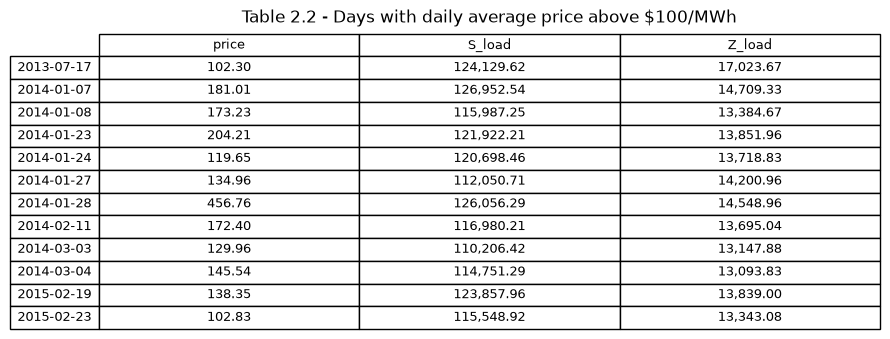

In [14]:
# Extreme price spikes (> $100/MWh)
spikes = daily_PJM_data[daily_PJM_data["price"] > 100]
table_figure(spikes, "Table 2.2 - Days with daily average price above $100/MWh",
             row_labels=spikes.index.strftime("%Y-%m-%d"), 
             decimals=2, 
             figsize=(9, 3.5))


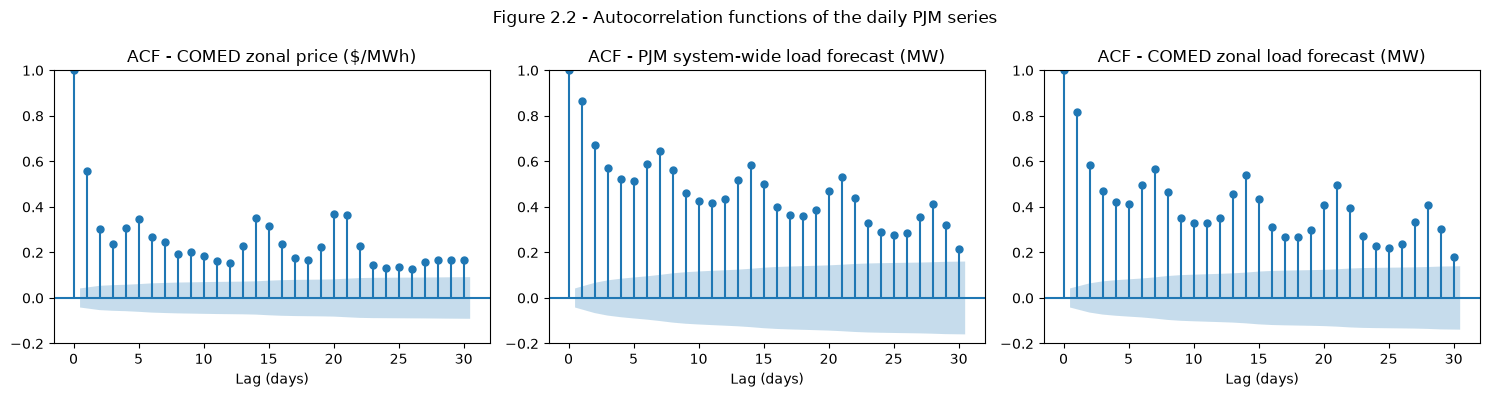

In [15]:
# Autocorrelation functions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, labels):
    plot_acf(daily_PJM_data[col], lags=30, ax=ax)
    ax.set_title(f"ACF - {labels[col]}")
    ax.set_xlabel("Lag (days)")
    ax.set_ylim(-0.2, 1)

fig.suptitle("Figure 2.2 - Autocorrelation functions of the daily PJM series")
plt.tight_layout()
save_output(fig, "Figure 2.2 - ACF of daily PJM series")
plt.show()

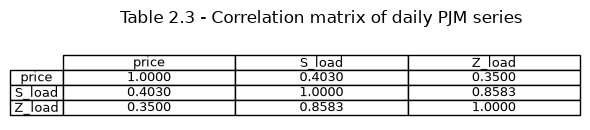

Corr(S_load, Z_load) = 0.8583


In [16]:
# Correlation between S_load and Z_load
corr = daily_PJM_data.corr()
# Calling the table formatting function above
table_figure(corr, "Table 2.3 - Correlation matrix of daily PJM series", decimals=4, figsize=(6, 1.4))
# Print correlation
print(f"Corr(S_load, Z_load) = {corr.loc['S_load', 'Z_load']:.4f}")

## 2b. `Q2_AR()` [5 pts]
Function taking Series `y`, `lag` (int or 'aic'/'bic'/'hqic') and `max_lag` (int or None); returns an `AutoRegResults` object.

Source used: [Statsmodels - AutoReg & ar_select_order](https://www.statsmodels.org/stable/examples/notebooks/generated/autoregressions.html)

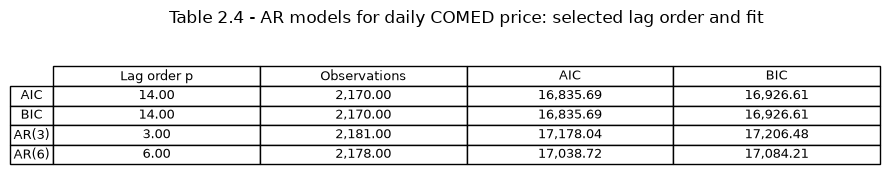

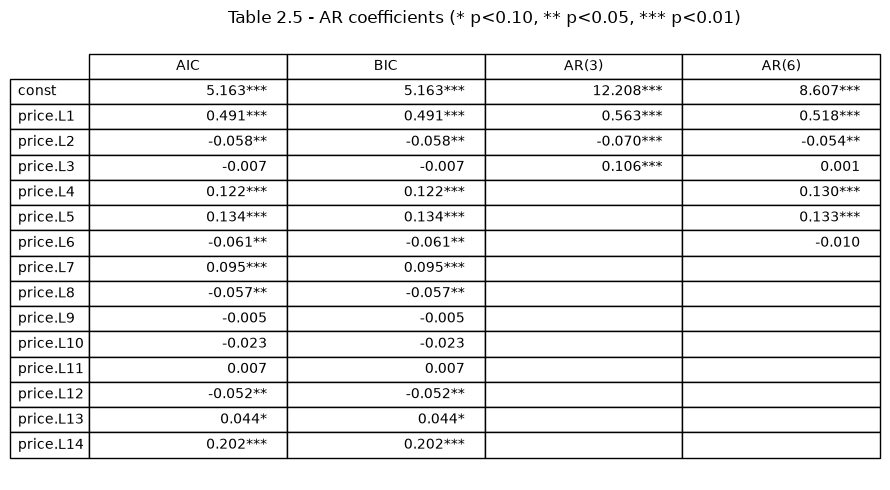

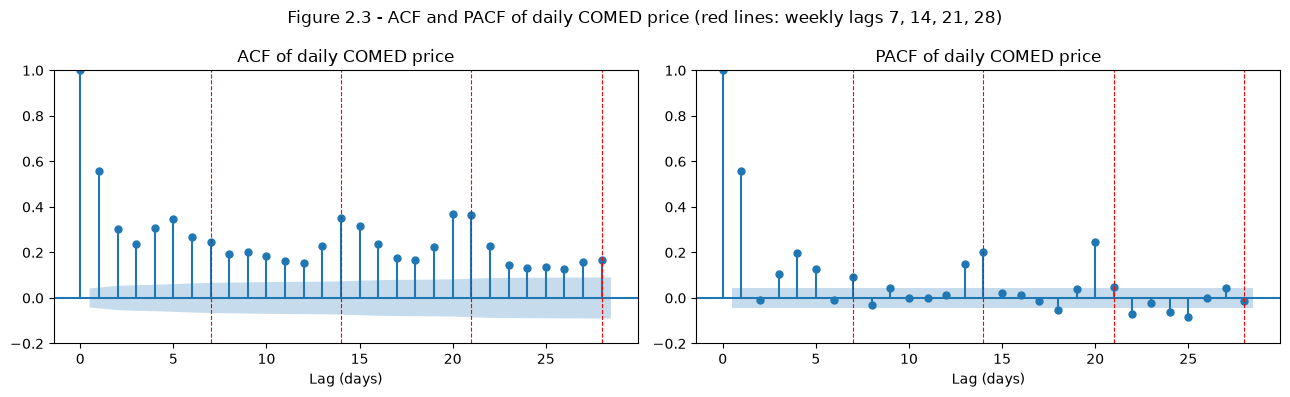

In [17]:
def Q2_AR(y, lag, max_lag=None):
    """Fit an AR(p) model to a series, with p fixed or chosen by an information criterion.

    Parameters
    ----------
    y : array-like or pd.Series
        The series (daily COMED price).
    lag : int or str
        Integer -> fit AR(lag) directly.
        'aic', 'bic' or 'hqic' -> select p in 1..max_lag with that criterion.
    max_lag : int, optional
        Largest order considered when lag is a criterion.

    Returns
    -------
    statsmodels AutoRegResults
        Fitted AR model.
    """
    if isinstance(lag, str):                                   # 'aic', 'bic' or 'hqic' -> let the criterion pick p
        selection = ar_select_order(y, maxlag=max_lag, ic=lag.lower())   # compares AR(1)..AR(max_lag) on a common sample
        
        return selection.model.fit()                           
    
    return AutoReg(y, lags=lag).fit()                          


# Applying the function to the daily price series
# "lag = 'aic' and lag = 'bic' with max_lag = 14, and also using lag = 3 and lag = 6 directly"
price = daily_PJM_data['price']
specs_2b = {'AIC': ('aic', 14), 'BIC': ('bic', 14), 'AR(3)': (3, None), 'AR(6)': (6, None)}

res_2b = {}
for name, (lag, max_lag) in specs_2b.items():
    res_2b[name] = Q2_AR(price, lag, max_lag)

# Table 2.4: lag order selected / used by each model
summary = {}
for name, res in res_2b.items():                         # one row of Table 2.4 per model
    summary[name] = {'Lag order p': max(res.model.ar_lags),
                     'Observations': res.nobs,
                     'AIC': res.aic,
                     'BIC': res.bic}

summary_2b = pd.DataFrame(summary).T

table_figure(summary_2b, "Table 2.4 - AR models for daily COMED price: selected lag order and fit",
             decimals=2, figsize=(9, 2))


# Table 2.5: coefficients side by side (blank = lag not in the model), stars on p-values
def stars(p):
    """Significance stars for a p-value: *** p<0.01, ** p<0.05, * p<0.10, '' otherwise."""
    if p < 0.01:
        return '***'
    elif p < 0.05:
        return '**'
    elif p < 0.10:
        return '*'
    else:
        return ''


longest = max(res_2b.values(), key=lambda r: len(r.params)).params.index   # const, L1, ..., L_pmax in order
coef_columns = {}

for name, res in res_2b.items():                         # one column of Table 2.5 per model
    cells = []
    
    for b, p in zip(res.params, res.pvalues):            # coefficient + its significance stars
        cells.append(f"{b:.3f}{stars(p)}")
    
    coef_columns[name] = pd.Series(cells, index=res.params.index)


coef_2b = pd.concat(coef_columns, axis=1).reindex(longest).fillna('')

title_2b = "Table 2.5 - AR coefficients (* p<0.10, ** p<0.05, *** p<0.01)"
fig, ax = plt.subplots(figsize=(9, 5))
ax.axis('off')
ax.table(cellText=coef_2b.values, rowLabels=coef_2b.index, colLabels=coef_2b.columns,
         loc='center').scale(1, 1.3)
ax.set_title(title_2b)
plt.tight_layout()
save_output(fig, title_2b)                                     # text table, so saved here instead of via table_figure
plt.show()

# Weekly structure: ACF / PACF of price, with the weekly lags (7, 14, 21, 28) marked
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(price, lags=28, ax=axes[0], title='ACF of daily COMED price')
plot_pacf(price, lags=28, ax=axes[1], title='PACF of daily COMED price', method='ywm')

for ax in axes:
    
    for k in (7, 14, 21, 28):
        ax.axvline(k, color='red', ls='--', lw=0.8)                # weekly lags
    
    ax.set_xlabel('Lag (days)')
    ax.set_ylim(-0.2, 1)

fig.suptitle("Figure 2.3 - ACF and PACF of daily COMED price (red lines: weekly lags 7, 14, 21, 28)")
plt.tight_layout()
save_output(fig, "Figure 2.3 - ACF and PACF of daily price")
plt.show()

## 2c. `Q2_Forecast()` [5 pts]
Function taking an `AutoRegResults` `res` and `hmax`; returns a 1-D array of out-of-sample forecasts. Apply to all part (b) models with hmax = 24.

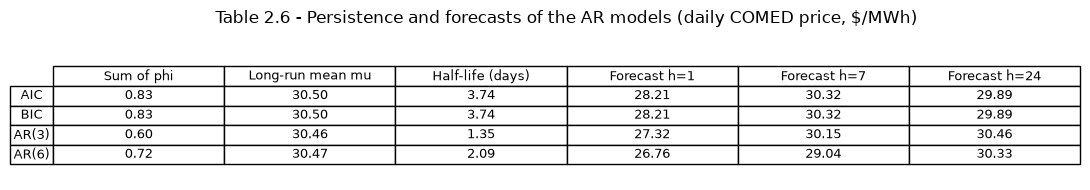

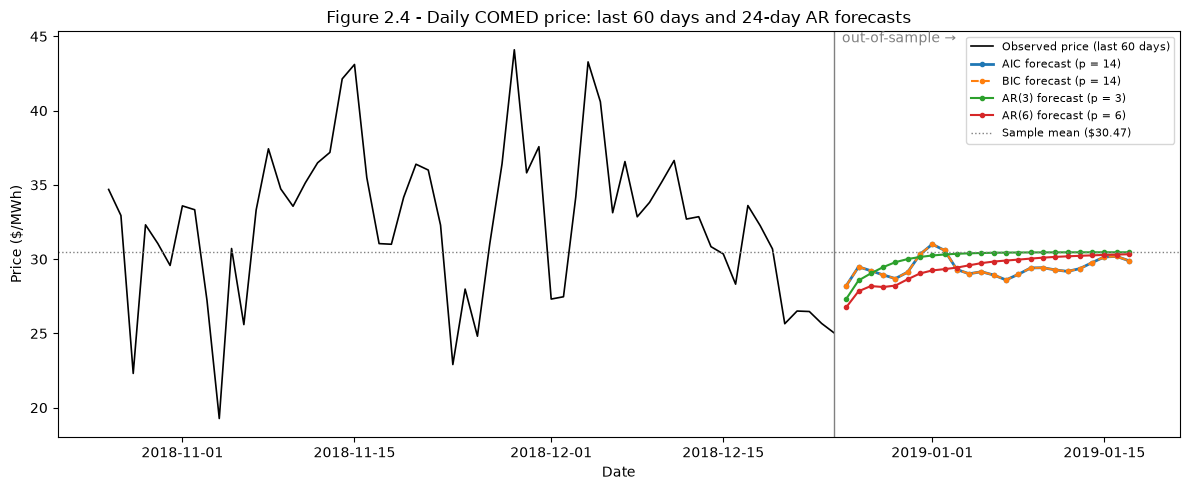

In [18]:
def Q2_Forecast(res, hmax):
    """Out-of-sample forecasts from a fitted AR model, for horizons 1..hmax.

    Forecasts are iterated: from h = 2 on, earlier forecasts replace the
    future prices that are not yet known.

    Parameters
    ----------
    res : statsmodels AutoRegResults
        Fitted AR model (e.g. from Q2_AR()).
    hmax : int
        Number of steps ahead.

    Returns
    -------
    np.ndarray
        1-D array of length hmax: forecasts for h = 1, ..., hmax.
    """
    # recursive (iterated) forecasts: from h = 2 onwards, earlier forecasts replace the unknown future prices
    return np.asarray(res.forecast(steps=hmax))

# Applying the function to every AR model from part (b)
hmax = 24
fc_2c = {}

for name, res in res_2b.items():                         # 24-day forecast path of each model
    fc_2c[name] = Q2_Forecast(res, hmax)

fc_dates = pd.date_range(price.index[-1] + pd.Timedelta(days=1), periods=hmax, freq='D')   # out-of-sample dates


# Table 2.6: long-run mean, persistence and a few forecast horizons for each model
def unconditional_mean(res):
    """Long-run (unconditional) mean of a fitted AR model: mu = c / (1 - sum of phis).

    Parameters
    ----------
    res : statsmodels AutoRegResults
        Fitted AR model with a constant as its first parameter.

    Returns
    -------
    float
        The level that the forecasts converge to as h grows.
    """
    c, phis = res.params.iloc[0], res.params.iloc[1:]          # const, then phi_1 .. phi_p
    
    return c / (1 - phis.sum())                                # mu = c / (1 - sum(phi))


persistence = {}
for name, res in res_2b.items():                         # one row of Table 2.6 per model
    persistence[name] = {
        'Sum of phi': res.params.iloc[1:].sum(),
        'Long-run mean mu': unconditional_mean(res),
        'Half-life (days)': np.log(0.5) / np.log(res.params.iloc[1:].sum()),   # AR(1)-equivalent approximation
        'Forecast h=1': fc_2c[name][0],
        'Forecast h=7': fc_2c[name][6],
        'Forecast h=24': fc_2c[name][-1]}

persistence_2c = pd.DataFrame(persistence).T

table_figure(persistence_2c, "Table 2.6 - Persistence and forecasts of the AR models (daily COMED price, $/MWh)",
             decimals=2, figsize=(11, 2))

# Plot: last 60 in-sample days + the 24-day forecasts of each model
last60 = price.iloc[-60:]
styles = {'AIC': dict(color='tab:blue', lw=2),
          'BIC': dict(color='tab:orange', ls='--', lw=1.5),         # dashed: AIC and BIC pick the same AR(14)
          'AR(3)': dict(color='tab:green', lw=1.5),
          'AR(6)': dict(color='tab:red', lw=1.5)}

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(last60.index, last60, color='black', lw=1.2, label='Observed price (last 60 days)')

for name, path in fc_2c.items():
    p = max(res_2b[name].model.ar_lags)
    ax.plot(fc_dates, path, marker='o', ms=3, label=f'{name} forecast (p = {p})', **styles[name])

ax.axvline(price.index[-1], color='grey', ls='-', lw=1)            # end of sample
ax.axhline(price.mean(), color='grey', ls=':', lw=1, label=f'Sample mean (${price.mean():.2f})')
ax.text(price.index[-1], ax.get_ylim()[1], '  out-of-sample →', va='top', color='grey')
ax.set_title('Figure 2.4 - Daily COMED price: last 60 days and 24-day AR forecasts')
ax.set_xlabel('Date')
ax.set_ylabel('Price ($/MWh)')
ax.legend(fontsize=8)
plt.tight_layout()
save_output(fig, "Figure 2.4 - AR forecasts of daily price, 24 days ahead")
plt.show()

## 2d. `Q2_RollForecast()` [5 pts]
Function taking array `s` and integers `T0`, `p`, `h`; rolling fixed-window AR(p) estimation, returns an array of shape (n_windows, h) of forecasts. Apply with T0 = 300, p ∈ {3, 6}, h = 24.

N = 2184, windows = 1861, forecast array shape = (1861, 24)


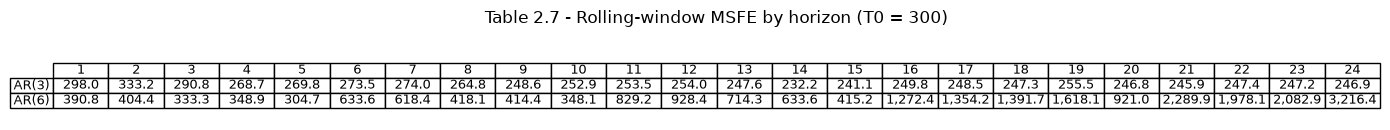

In [19]:
# Function to compute rolling forecasts for an AR(p) model
def Q2_RollForecast(s, T0, p, h):
    """Rolling fixed-window AR(p) forecasts.

    For each window of T0 consecutive observations, re-estimate AR(p) on that
    window only and forecast the next h days. The window then moves forward
    by one day.

    Parameters
    ----------
    s : array-like
        The series (daily COMED price).
    T0 : int
        Window length (number of observations used in each estimation).
    p : int
        AR order.
    h : int
        Maximum forecast horizon.

    Returns
    -------
    np.ndarray
        Shape (n_windows, h): row i = forecasts for h = 1..h from window i.
    """
    s = np.asarray(s, dtype=float)
    n_windows = len(s) - T0 - h + 1                  # last window still has h realised values after it
    forecasts = np.empty((n_windows, h))
    
    # Loop over all windows, re-estimate AR(p) on each window, and forecast h steps ahead
    for i in range(n_windows):
        window = s[i:i + T0]                         
        res = AutoReg(window, lags=p).fit()          # re-estimate AR(p) on this window only
        forecasts[i] = res.forecast(h)               
    
    return forecasts                                 


# Building the matching array of realised values
def Q2_Realised(s, T0, h):
    """Actual values matching the forecasts of Q2_RollForecast().

    Parameters
    ----------
    s : array-like
        The series (daily COMED price).
    T0 : int
        Window length (same as in Q2_RollForecast()).
    h : int
        Maximum forecast horizon.

    Returns
    -------
    np.ndarray
        Shape (n_windows, h): row i = the h values observed right after window i.
        Forecast errors are then realised - forecasts.
    """
    s = np.asarray(s, dtype=float)
    n_windows = len(s) - T0 - h + 1
    realised = []
    
    for i in range(n_windows):                       # the h values right after window i
        realised.append(s[i + T0:i + T0 + h])
    
    return np.array(realised)


# setting the function parameters for the rolling forecasts
T0, h = 300, 24
forecast_ar3 = Q2_RollForecast(price, T0, 3, h)
forecast_ar6 = Q2_RollForecast(price, T0, 6, h)
actual = Q2_Realised(price, T0, h)

# calculating the forecast errors for each model (Useful later for MSFE table)
errors_ar3, errors_ar6 = actual - forecast_ar3, actual - forecast_ar6

# printing the number of windows and the shape of the forecast arrays
print(f"N = {len(price)}, windows = {forecast_ar3.shape[0]}, forecast array shape = {forecast_ar3.shape}")

# prep table of MSFE
msfe_2d = pd.DataFrame({'AR(3)': (errors_ar3 ** 2).mean(axis=0),
                        'AR(6)': (errors_ar6 ** 2).mean(axis=0)},
                       index=pd.Index(range(1, h + 1), name='h')).T

# Calling the table formatting function above
table_figure(msfe_2d, "Table 2.7 - Rolling-window MSFE by horizon (T0 = 300)",
             decimals=1, figsize=(14, 1.4))


## 2e. `Q2_DM()` – Equal MSFE test [10 pts]
Function taking loss differentials `d` and horizon `h`; returns the Diebold–Mariano statistic. Test H0: AR(3) and AR(6) have equal MSFE for h = 1..24.

In [20]:
# - Build Q2_DM(d, h) (HAC / long-run variance with h-1 lags)
# - Loss differential d = e_AR3^2 - e_AR6^2 for each horizon (from 2d forecasts)
# - DM stat + two-sided p-value for h = 1..24 -> single table
# - Single plot of DM stats with +/-1.645 reference lines
# - Write-up: (i) significant horizons, (ii) lag-7 / day-of-week, (iii) stationarity & polar vortex

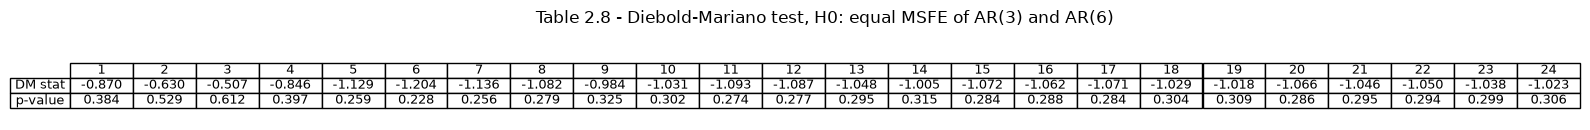

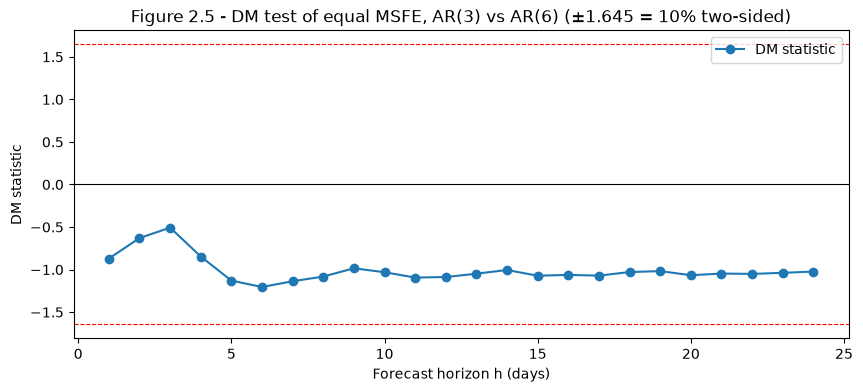

Worst AR(6) window ends on 2014-01-28 | 24-step error AR(6) = -1714, AR(3) = -83


In [21]:
def Q2_DM(d, h):
    """Diebold-Mariano statistic for H0: E[d] = 0.

    The statistic is mean(d) divided by its standard error. The variance uses
    a Newey-West (Bartlett-weighted) long-run variance with h - 1
    autocovariances, because h-step forecast errors overlap.

    Parameters
    ----------
    d : array-like
        Loss differential, one value per forecast.
        Equal MSFE (2e): d = e_AR3^2 - e_AR6^2.
        Encompassing (2f): d = e_AR3 * (e_AR3 - e_AR6).
    h : int
        Forecast horizon.

    Returns
    -------
    float
        DM statistic, approximately N(0, 1) under H0.
    """
    d = np.asarray(d, dtype=float)
    T = len(d)
    u = d - d.mean()
    lrv = u @ u / T                                      
    
    for k in range(1, h):                                # h-1 autocovariances (MA(h-1) under H0)
        lrv += 2 * (1 - k / h) * (u[k:] @ u[:-k]) / T    # Bartlett weighted variance (keeps it positive)
    
    return d.mean() / np.sqrt(lrv / T)                   # ~ N(0,1) under H0: E[d] = 0


# Loss differential at d > 0 means AR(3) has the larger squared error (AR(6)) (so AR(6) is better))
H = range(1, h + 1)
dm_2e = pd.DataFrame(index=['DM stat', 'p-value'], columns=pd.Index(H, name='h'), dtype=float)

for k in H:
    d = errors_ar3[:, k - 1] ** 2 - errors_ar6[:, k - 1] ** 2
    stat = Q2_DM(d, k)
    dm_2e[k] = [stat, 2 * stats.norm.sf(abs(stat))]     # two-sided p-value

# Calling the table formatting function above
table_figure(dm_2e, "Table 2.8 - Diebold-Mariano test, H0: equal MSFE of AR(3) and AR(6)",
             decimals=3, figsize=(16, 1.4))

# Plot of DM statistics (±1.645 reference lines)
fig = plt.figure(figsize=(10, 4))
plt.plot(list(H), dm_2e.loc['DM stat'], marker='o', label='DM statistic')

for c in (1.645, -1.645):
    plt.axhline(c, color='red', ls='--', lw=0.8)

plt.axhline(0, color='black', lw=0.8)
plt.xlabel('Forecast horizon h (days)')
plt.ylabel('DM statistic')
plt.title('Figure 2.5 - DM test of equal MSFE, AR(3) vs AR(6) (±1.645 = 10% two-sided)')
plt.legend()
save_output(fig, "Figure 2.5 - DM statistics, equal MSFE AR(3) vs AR(6)")
plt.show()

# Window with the largest AR(6) error (for the write-up)
worst = np.argmax(np.abs(errors_ar6[:, -1]))

# Print the window with the largest AR(6)
print("Worst AR(6) window ends on", price.index[worst + T0 - 1].date(),
      f"| 24-step error AR(6) = {errors_ar6[worst, -1]:.0f}, AR(3) = {errors_ar3[worst, -1]:.0f}")


## 2f. Forecast encompassing test [10 pts]
Use `Q2_DM()` to test H0: AR(3) forecast-encompasses AR(6), same rolling setup as (e), h = 1..24.

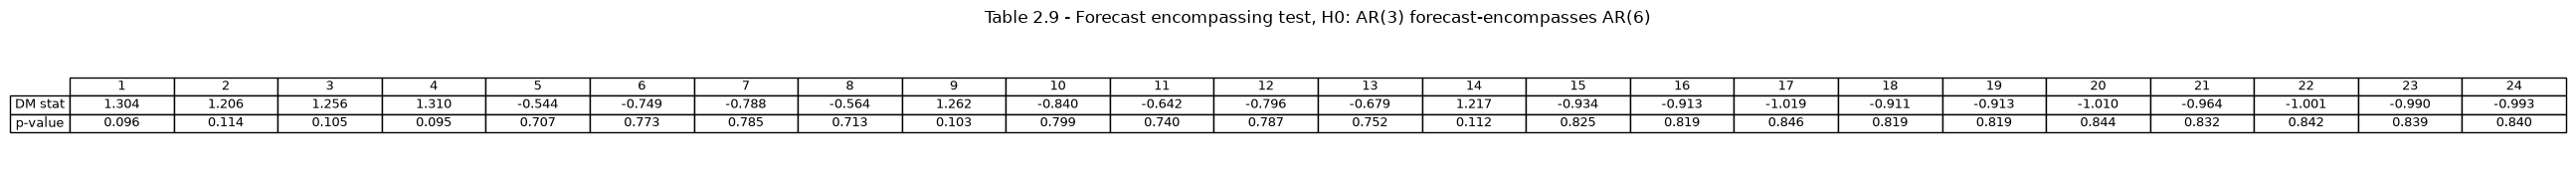

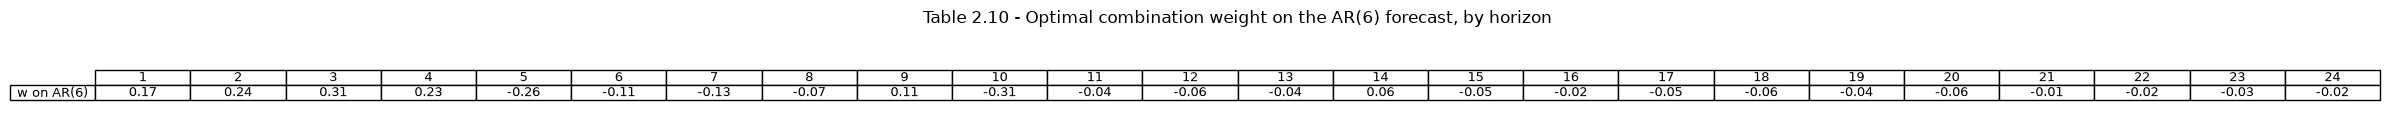

5 outlier windows, ending 2014-01-28 to 2014-02-01; they account for 50%-97% of sum|d| across horizons


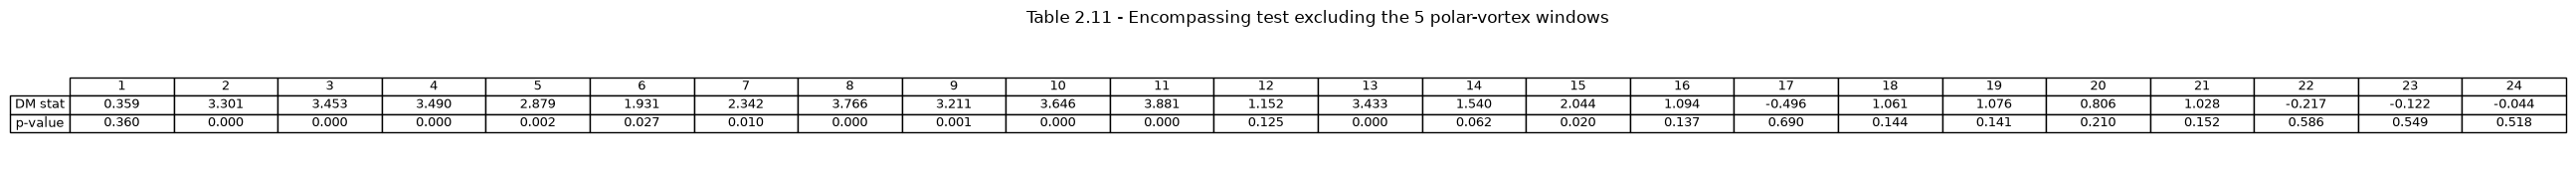

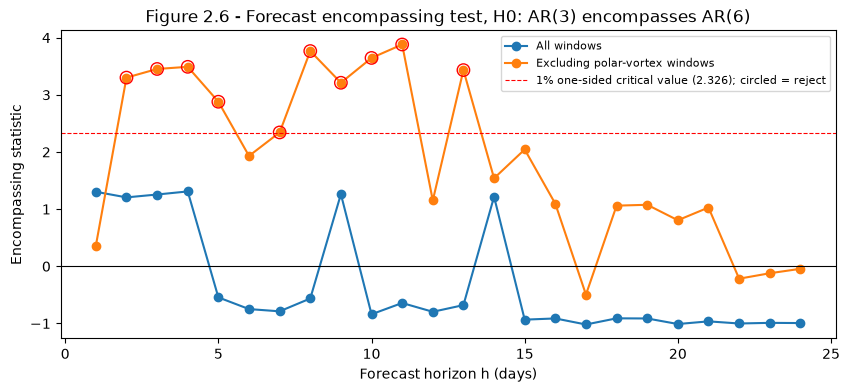

AR(6) NOT encompassed by AR(3) at 99% (all windows): []
AR(6) NOT encompassed by AR(3) at 99% (excluding polar-vortex windows): [2, 3, 4, 5, 7, 8, 9, 10, 11, 13]


In [23]:
def Q2_Encompass(e_small, e_big, horizons):
    """Forecast-encompassing test at each horizon, using Q2_DM().

    H0: the small model forecast-encompasses the big model (the big model
    adds no information, so its weight in a combination is zero).
    d_t = e_small,t * (e_small,t - e_big,t). The test is one-sided:
    reject when the statistic is large and positive.

    Parameters
    ----------
    e_small : np.ndarray
        Forecast errors of the small model (AR(3)), shape (n_windows, H).
    e_big : np.ndarray
        Forecast errors of the big model (AR(6)), same shape.
    horizons : iterable of int
        Horizons to test (e.g. 1..24).

    Returns
    -------
    pd.DataFrame
        Rows 'DM stat' and 'p-value' (one-sided, P(Z > stat)); one column per horizon.
    """
    # H0: the small model (AR(3)) forecast-encompasses the big model (AR(6)), i.e. AR(6) adds no information.
    # Encompassing loss differential: d_t = e_small,t * (e_small,t - e_big,t), so E[d] = 0 under H0.
    # Under H1 the AR(6) forecast still helps, which pushes E[d] > 0  ->  one-sided (upper-tail) test.
    out = pd.DataFrame(index=['DM stat', 'p-value'], columns=pd.Index(horizons, name='h'), dtype=float)
    
    for k in horizons:
        d = e_small[:, k - 1] * (e_small[:, k - 1] - e_big[:, k - 1])
        stat = Q2_DM(d, k)                                  # same HAC statistic as in 2e, h-1 autocovariances
        out[k] = [stat, stats.norm.sf(stat)]                # one-sided p-value: P(Z > stat)
    
    return out


# Same rolling setup as 2e: T0 = 300, AR(3) vs AR(6), h = 1..24
enc_2f = Q2_Encompass(errors_ar3, errors_ar6, H)

# Calling the table formatting function above
table_figure(enc_2f, "Table 2.9 - Forecast encompassing test, H0: AR(3) forecast-encompasses AR(6)",
             decimals=3, figsize=(26, 1.8))

# For the interpretation: weight on AR(6) in the optimal combination (1 - w) * f_AR3 + w * f_AR6
# OLS of e_AR3 on (e_AR3 - e_AR6) without constant: w = 0 under H0, w = 1 if AR(6) alone is best
diff = errors_ar3 - errors_ar6
weights_2f = pd.DataFrame({'w on AR(6)': (errors_ar3 * diff).sum(axis=0) / (diff ** 2).sum(axis=0)},
                          index=pd.Index(H, name='h')).T

# calling the table formatting function above
table_figure(weights_2f, "Table 2.10 - Optimal combination weight on the AR(6) forecast, by horizon",
             decimals=2, figsize=(24, 1.4))

# Robustness: a handful of windows right after the January 2014 polar vortex produce explosive AR(6)
# forecasts (24-step errors above $1,000/MWh) and dominate both the DM and the encompassing statistics.
outlier = np.abs(errors_ar6).max(axis=1) > 500                       # windows with any |AR(6) error| > $500/MWh
end_dates = price.index[np.where(outlier)[0] + T0 - 1].date           # last in-sample day of each such window
share = np.sort(np.abs(errors_ar3 * diff), axis=0)[-outlier.sum():].sum(axis=0) / np.abs(errors_ar3 * diff).sum(axis=0)

print(f"{outlier.sum()} outlier windows, ending {end_dates[0]} to {end_dates[-1]}; "
      f"they account for {share.min():.0%}-{share.max():.0%} of sum|d| across horizons")

enc_2f_robust = Q2_Encompass(errors_ar3[~outlier], errors_ar6[~outlier], H)

# calling the table formatting function above
table_figure(enc_2f_robust, f"Table 2.11 - Encompassing test excluding the {outlier.sum()} polar-vortex windows",
             decimals=3, figsize=(26, 1.8))

# Plot of the encompassing statistics (full sample and robustness) with the 1% one-sided critical value
crit_99 = stats.norm.ppf(0.99)                              # 2.326
fig = plt.figure(figsize=(10, 4))

for res_enc, lab, col in [(enc_2f, 'All windows', 'tab:blue'),
                          (enc_2f_robust, 'Excluding polar-vortex windows', 'tab:orange')]:
    
    reject = (res_enc.loc['p-value'] < 0.01).values
    
    plt.plot(list(H), res_enc.loc['DM stat'], marker='o', color=col, label=lab)
    plt.scatter(np.array(H)[reject], res_enc.loc['DM stat'].values[reject], s=80,
                facecolors='none', edgecolors='red', zorder=3)

plt.axhline(crit_99, color='red', ls='--', lw=0.8, label=f'1% one-sided critical value ({crit_99:.3f}); circled = reject')
plt.axhline(0, color='black', lw=0.8)
plt.xlabel('Forecast horizon h (days)')
plt.ylabel('Encompassing statistic')
plt.title('Figure 2.6 - Forecast encompassing test, H0: AR(3) encompasses AR(6)')
plt.legend(fontsize=8)
save_output(fig, "Figure 2.6 - Encompassing statistics, AR(3) vs AR(6)")
plt.show()

for res_enc, lab in [(enc_2f, 'all windows'), (enc_2f_robust, 'excluding polar-vortex windows')]:
    rejected = []
    
    for k in H:
        if res_enc.loc['p-value', k] < 0.01:
            rejected.append(k)
    
    print(f"AR(6) NOT encompassed by AR(3) at 99% ({lab}):", rejected)

# Problem 3 – VAR Models [30 pts]
Daily-averaged PJM data; variables [price, Z_load, S_load].

Source: [Medium - VAR Model in Python](https://medium.com/@ngaridennis3/developing-a-vector-autoregressive-model-in-python-698d064982c4)

## 3a. `Q3_VARlag()` [10 pts]
Function taking DataFrame `df` and list `maxlags`; returns a len(maxlags) × 3 DataFrame `IC_lags` of AIC/BIC/HQIC-optimal VAR lag lengths. Apply with maxlags = [7, 14, 21].

Source used: [Vector Autoregression](https://www.statsmodels.org/stable/vector_ar.html)

Source used: [StatsModels - Lag Order Results](https://www.statsmodels.org/stable/generated/statsmodels.tsa.vector_ar.var_model.LagOrderResults.html#statsmodels.tsa.vector_ar.var_model.LagOrderResults)

In [24]:
# - Build Q3_VARlag(df, maxlags): loop over maxlags, VAR(df).select_order(m)
# - Variables: [price, Z_load, S_load]
# - Report IC_lags table
# - Write-up: (i) IC agreement, (ii) 7-day cycle, (iii) S_load/Z_load collinearity effect

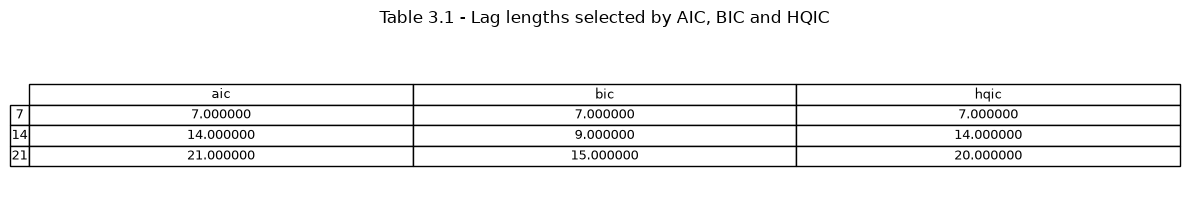

In [25]:
def Q3_VARlag(df, maxlags):
    """Lag order selected by AIC, BIC and HQIC for a VAR, for several maximum lags.

    Parameters
    ----------
    df : pd.DataFrame
        The VAR variables (one column each).
    maxlags : list of int
        Maximum lag orders to try.

    Returns
    -------
    pd.DataFrame
        One row per maxlag, columns 'aic', 'bic', 'hqic' = selected lag order.
    """
    rows = []
    
    for m in maxlags:
        sel = VAR(df).select_order(maxlags=m).selected_orders   # Dict: 'aic', 'bic', 'hqic' - StatsModels: Lag Order Results
        rows.append([sel['aic'], sel['bic'], sel['hqic']])
    
    return pd.DataFrame(rows, index=maxlags, columns=['aic', 'bic', 'hqic'])


# Applying the function with maxlags = [7, 14, 21]
# df_pjm (daily [price, Z_load, S_load]) is built in the Data loading cell
IC_lags = Q3_VARlag(df_pjm, [7, 14, 21])

#Reporting the IC_lags Table
table_figure(IC_lags, "Table 3.1 - Lag lengths selected by AIC, BIC and HQIC")

## 3b. `Q3_Granger()` [10 pts]
Function taking `VARResults` `res` and `lag`; returns an N × N DataFrame of Granger F-stats where entry (i, j) tests that j does not Granger-cause i. Apply to the VAR at the BIC lag from (a).

Source used: [Machine Learning Plus - Granger Causality Test](https://machinelearningplus.com/time-series/granger-causality-test-in-python/)

In [26]:
# - Build Q3_Granger(res, lag): loop over ordered pairs, res.test_causality(caused=i, causing=j)
# - Fit VAR at BIC-selected lag from 3a
# - Report full F-stat matrix (+ p-values)
# - Write-up: (i) direction price <-> loads, (ii) collinearity issue, (iii) predictive vs structural causality

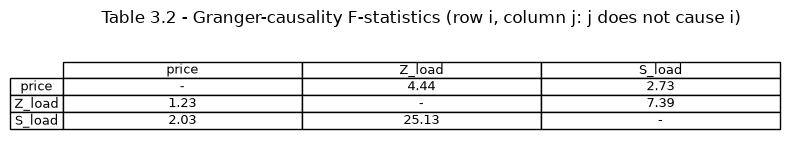

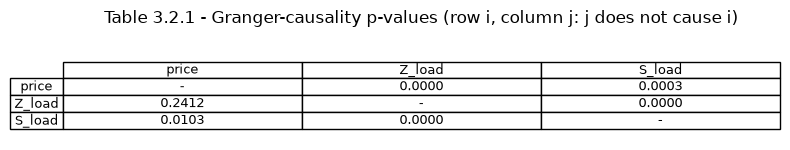

In [27]:
def Q3_Granger(res, lag):
    """Pairwise Granger-causality F statistics from a fitted VAR.

    Parameters
    ----------
    res : statsmodels VARResults
        Fitted VAR.
    lag : int
        Lag order to use; the VAR is refitted if it differs from res.k_ar.

    Returns
    -------
    pd.DataFrame
        Entry (row i, column j) = F statistic for H0: j does not Granger-cause i.
        The diagonal is NaN.
    """
    if lag != res.k_ar:                              # To make sure the VAR uses the requested lag
        res = res.model.fit(lag)
    
    names = res.names                                # [price, Z_load, S_load]
    F = pd.DataFrame(np.nan, index=names, columns=names)
    
    for i in names:                                  # i = caused variable (row)
        
        for j in names:                              # j = causing variable (column)
            if i != j:
                F.loc[i, j] = res.test_causality(caused=i, causing=j, kind='f').test_statistic
    
    return F


# Applying the function at the lag length selected by BIC in part (a)
lag_bic = int(IC_lags.loc[21, 'bic'])               # Check that all three BIC rows agree
res_var = VAR(df_pjm).fit(lag_bic)
F_matrix = Q3_Granger(res_var, lag_bic)

table_figure(F_matrix, "Table 3.2 - Granger-causality F-statistics (row i, column j: j does not cause i)",
             decimals=2, figsize=(8, 1.6))

# p-values, to help with the interpretation
K = res_var.neqs
p_matrix = pd.DataFrame(stats.f.sf(F_matrix, lag_bic, K * res_var.df_resid),
                        index=F_matrix.index, columns=F_matrix.columns)

table_figure(p_matrix, "Table 3.2.1 - Granger-causality p-values (row i, column j: j does not cause i)",
             decimals=4, figsize=(8, 1.6));

## 3c. VAR(7) impulse responses [10 pts]
Estimate a VAR(7) for [price, Z_load, S_load]; plot IRFs of all three variables to a 1-s.d. `Z_load` shock over 21 periods, with confidence bands and a dashed line at h = 7.

In [28]:
# - Fit VAR(7), ordering [price, Z_load, S_load]
# - Orthogonalised (Cholesky) IRFs, 21 periods, with confidence bands
# - Plot responses to the Z_load shock, dashed vertical line at h = 7
# - Write-up: (i) short-lived vs persistent, (ii) price response intuition, (iii) ordering / swapping Z_load & S_load

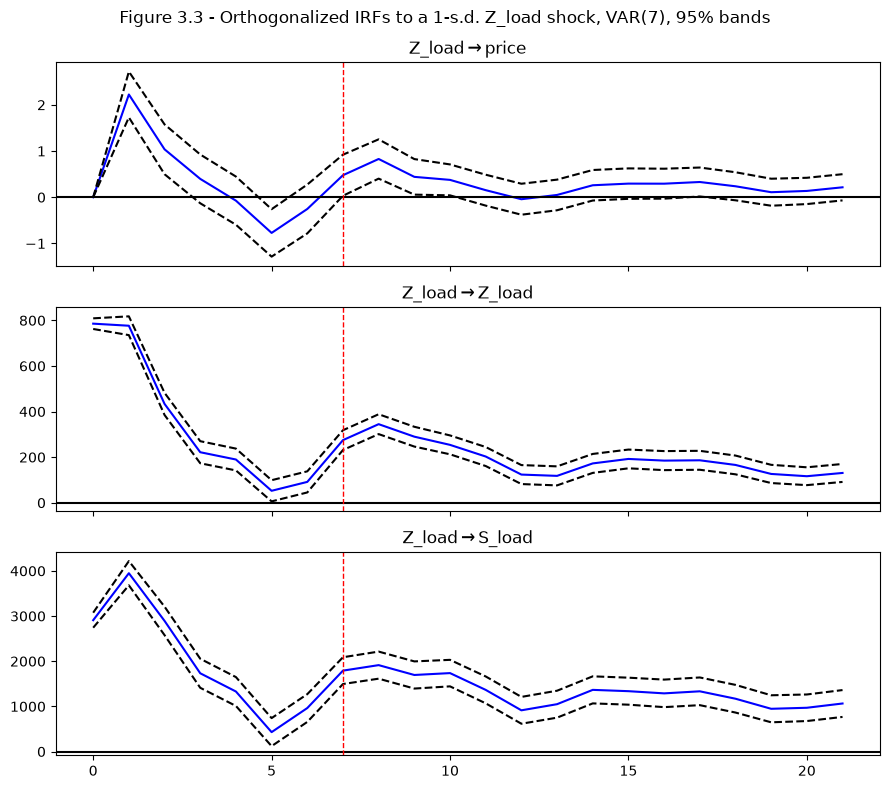

In [29]:
res7 = VAR(df_pjm).fit(7)                                                     # VAR(7) for [price, Z load, S load]
irf = res7.irf(21)                                                            # Impulse responses, 21 periods ahead

fig = irf.plot(orth=True, impulse='Z_load', signif=0.05, figsize=(9, 8))

for ax in fig.axes:                                                           # One panel per responding variable
    ax.axvline(7, color='red', linestyle='--', linewidth=1)                   # End of the first week (h = 7)

fig.suptitle("Figure 3.3 - Orthogonalized IRFs to a 1-s.d. Z_load shock, VAR(7), 95% bands")
plt.tight_layout()
save_output(fig, "Figure 3.3 - IRFs to a Z_load shock, VAR(7)")
plt.show()

        price  Z_load  S_load
price   1.000   0.215   0.318
Z_load  0.215   1.000   0.596
S_load  0.318   0.596   1.000


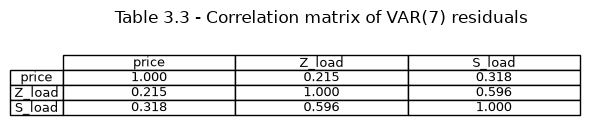

In [30]:
# Correlation matrix of the VAR residuals, to help with the interpretation of the IRFs
corr = pd.DataFrame(res_var.resid_corr, index=res_var.names, columns=res_var.names)
print(corr.round(3))
table_figure(corr, "Table 3.3 - Correlation matrix of VAR(7) residuals", decimals=3, figsize=(6, 1.4));